# LATTE: ESP through the observed eddy depth

Apply the ESP inner and Gaussian outer stages to each measured ADCP depth bin for the selected IN2021_V03 transect. This is an **ADCP-only** application. The paired notebooks use the same data window, starting centre, fitting controls, units and plot scales, with one shared `../esp_depth_tools.py` helper.

LATTE estimates an ellipse from the two-dimensional distribution of observed velocities. A nearly straight single transect may not constrain that ellipse, even with high R²; invalid geometry remains visible in the diagnostics.

“Surface” means the shallowest observed bin, **18 m**, not the sea surface. Track each accepted inner centre downwards; failed levels do not update the next initial guess. The deepest accepted fit is the limit of this reconstruction, **not a measurement of the eddy bottom**. The segment spans approximately 15 hours; reconstruction assumes sufficiently steady flow over that time.

**Saved-output provenance:** these outputs were executed locally using copies of the Katana ADCP CSV and ESP backend on 13 October 2026. The settings retain the Katana paths for rerunning there. Backend/data fingerprints and runtime versions are stored in notebook metadata.


In [1]:
from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the shared helper from the study folder or the UNSW-PhD repository root.
candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)


## Settings

The initial centre (150.35°E, 39.10°S) is a first approximation near the main surface velocity reversal in the existing selected transect. Edit it to select another eddy. East/north coordinates use this same origin in both notebooks. Positive fitted vorticity is anticyclonic here.

`MIN_ATTENDANCE=None` retains the original selection apart from missing positions/velocities. `Avg QC` is blank in this export, so no QC status is inferred; inspect the audit and set an attendance threshold only after deciding its interpretation. No background current is removed.


In [2]:
METHOD = "LATTE"
DATA_PATH = Path("/srv/scratch/z5297792/tilt_observation_data/MNF_IN2021_V03_adcp_trawler/MNF_IN2021_V03_adcp_trawler.csv")
BACKEND_PATH = Path("/home/z5297792/ESP_zonodo/functions.py")
START_UTC = "2021-05-08T23:30:00Z"
END_UTC = "2021-05-09T14:30:00Z"
ORIGIN_LON_LAT = (150.35, -39.10)
MIN_ATTENDANCE = None

FIT = dict(
    core_radius=35_000.,          # LATTE elliptical radius / SOLO along-track half-width
    outer_radius=100_000.,        # both: elliptical radius enclosing outer-stage data
    search_half_width=60_000.,    # SOLO crossing search about previous centre
    max_centre_step=35_000.,      # maximum accepted shift from previous centre
    radius_limit=100_000.,        # original backend's post-fit Gaussian radius limit
    min_core_points=8,
    min_outer_points=12,          # after the original circulation-sign filter
    expected_sign=1,              # +1 AE / -1 CE in this Southern Hemisphere case
    require_peak_bracket=True,    # sampled rho must straddle Rc/sqrt(2)
)
MAP_DEPTHS = (18, 100, 200, 300)  # nearest measured levels, including rejected fits
HALF_WIDTH_KM = 120
VELOCITY_LIMIT = 1.5             # identical colour limits for method comparisons


## Load and inspect the transect

The audit records the actual selected time span, depth coverage and backend fingerprint. There is no depth interpolation. All selected bins remain in the fit table, including bins left empty by filtering.


path                 /home/z5297792/ESP_zonodo/functions.py
sha256    8e4b06fe4c144f7a70671ee913b6d27784f9cdb587e9b0...
Name: ESP backend, dtype: object

selected_rows                                8076
used_rows                                    8076
unique_times                                  180
start_utc               2021-05-08 23:34:33+00:00
end_utc                 2021-05-09 14:29:34+00:00
depth_range_m                       [18.0, 410.0]
missing_avg_qc                               8076
zero_attendance_rows                         1693
min_attendance                               None
origin_lon_lat                    (150.35, -39.1)
Name: Selection audit, dtype: object

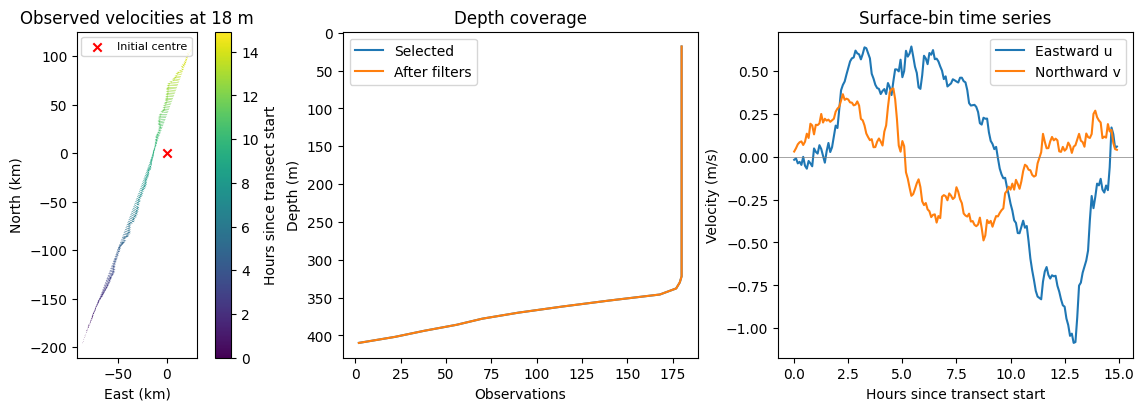

In [3]:
backend, backend_info = esp.load_backend(BACKEND_PATH)
data, coverage, audit = esp.load_observations(
    DATA_PATH, START_UTC, END_UTC, ORIGIN_LON_LAT, MIN_ATTENDANCE)
display(pd.Series(backend_info, name="ESP backend"))
display(pd.Series(audit, name="Selection audit"))
esp.plot_sampling(data, coverage)
plt.show()


## Fit from shallow to deep

LATTE reselects and fits its core twice at each depth, as in the multi-platform example. SOLO uses the backend estimator in the local crossing window. Both use the same Gaussian outer-stage objective and circulation-sign filter as `ESP_zonodo`, but the helper reports optimiser failures and radius-limit failures explicitly instead of returning initial guesses.

Accepted inner fits must have a positive-definite, determinant-one ellipse, the selected rotation sign and a centre shift within the specified limit. These are numerical/physical checks, not proof of parameter identifiability. The radius fit additionally needs sufficient points and, by default, sampling on both sides of the normalised velocity peak. Radius failure does not discard a valid inner centre. Full-field R²/RMSE use all observations inside the final outer footprint, including observations excluded by the outer fit's sign filter.


In [4]:
results, samples = esp.fit_depths(
    data, backend, METHOD, depth_levels=coverage.index, **FIT)
esp.report(results)
columns = ["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
           "core_spread_ratio", "inner_R2", "alpha", "Rc_m", "vector_R2"]
with pd.option_context("display.max_rows", 60):
    display(results[columns].round(4))


LATTE: 0/50 accepted inner fits; 0/50 accepted Gaussian reconstructions.
status
insufficient_core             6
insufficient_observations     1
invalid_ellipse              43
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,core_spread_ratio,inner_R2,alpha,Rc_m,vector_R2
0,18.0,invalid_ellipse,180,37,False,False,0.0003,0.9494,NaN,NaN,NaN
1,26.0,invalid_ellipse,180,37,False,False,0.0003,0.9557,NaN,NaN,NaN
2,34.0,invalid_ellipse,180,37,False,False,0.0003,0.9629,NaN,NaN,NaN
3,42.0,invalid_ellipse,180,37,False,False,0.0003,0.9653,NaN,NaN,NaN
4,50.0,invalid_ellipse,180,37,False,False,0.0003,0.9659,NaN,NaN,NaN
5,58.0,invalid_ellipse,180,37,False,False,0.0003,0.9685,NaN,NaN,NaN
6,65.9,invalid_ellipse,180,37,False,False,0.0003,0.9706,NaN,NaN,NaN
7,73.9,invalid_ellipse,180,37,False,False,0.0003,0.9752,NaN,NaN,NaN
8,81.9,invalid_ellipse,180,37,False,False,0.0003,0.9737,NaN,NaN,NaN
9,89.9,invalid_ellipse,180,37,False,False,0.0003,0.9687,NaN,NaN,NaN


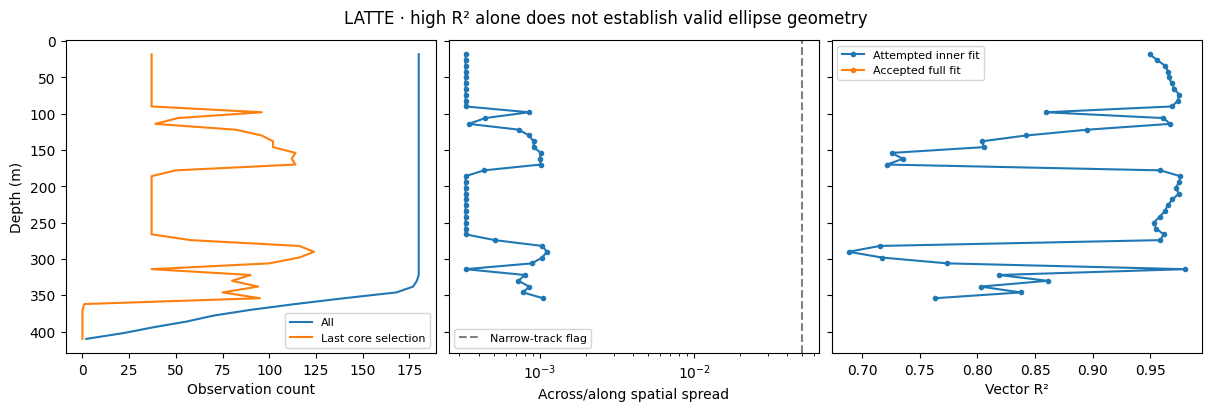

In [5]:
esp.plot_diagnostics(results)
plt.show()


## Centre trajectory and parameters

Offsets are **from the shallowest accepted inner centre to each deeper centre**, in geographic east/north coordinates. This is not the model climatology's saved deep-to-shallow delta-tilt statistic. `w = Omega × trace(Q)` is relative vorticity; it is distinct from the rotation parameter `Omega`. SOLO imposes axis ratio 1 and has no ellipse orientation.


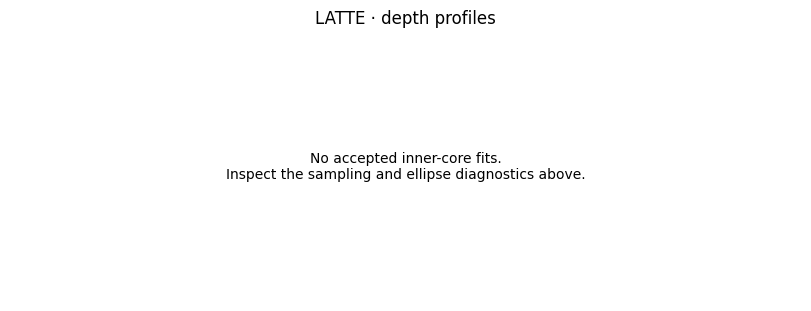

In [6]:
esp.plot_profiles(results)
plt.show()


## Horizontal reconstructions

Each panel uses the nearest measured bin to the requested depth, rather than silently replacing a rejected fit with another level. Black arrows show observations, grey arrows the reconstructed field. The red contour is `rho = Rc/sqrt(2)` (the peak of the normalised tangential profile); it is not the Gaussian radius `Rc`. The field away from the sampled transect is model-based extrapolation.


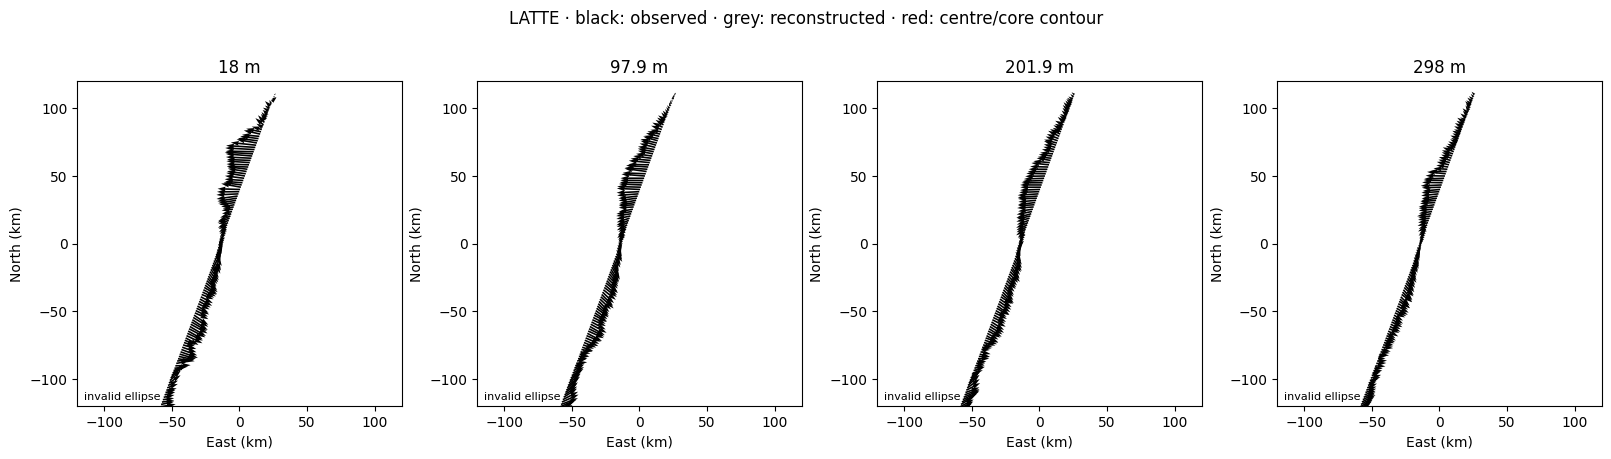

In [7]:
esp.plot_maps(results, samples, backend, depths=MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()


## Three-dimensional reconstruction

Stack selected core contours and horizontal flow vectors with the centreline. Only accepted Gaussian fits are drawn. Vertical scaling is exaggerated; no vertical velocity is inferred. A lack of accepted LATTE fits produces an explanatory panel rather than an invalid reconstruction.


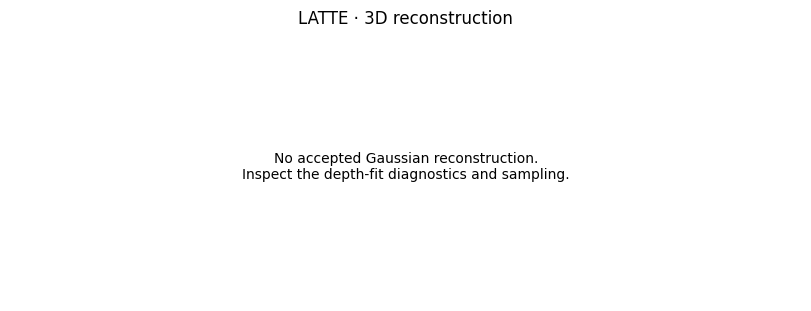

In [8]:
esp.plot_3d(results, backend, half_width_km=HALF_WIDTH_KM)
plt.show()


## Zonal and meridional sections

Fixed vertical planes pass through the shallowest accepted inner centre. The zonal section shows northward velocity `v`; the meridional section shows eastward velocity `u`. Dashed centre trajectories are **projections onto those planes**: deeper centres need not lie in the planes. White rows retain rejected fits. Rows represent actual observed depth bins, without vertical interpolation or extension to 0 m.


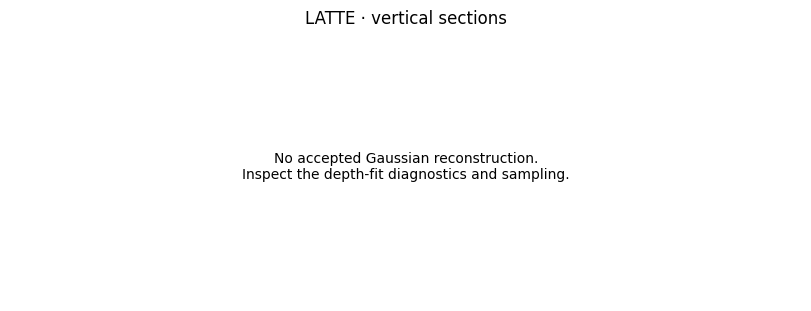

In [9]:
esp.plot_sections(results, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()


## Export to scratch

The full table includes rejected levels, inner and outer estimates, counts, diagnostics and warning text. Keep settings and the backend fingerprint with exported results. Run both notebooks with matching settings for a method comparison; their accepted depth ranges may differ.


In [10]:
SAVE_RESULTS = True
if SAVE_RESULTS:
    import json
    output = DATA_PATH.parent / "outputs"
    output.mkdir(parents=True, exist_ok=True)
    results.to_csv(output / f"{METHOD.lower()}_depth_fits.csv", index=False)
    provenance = dict(method=METHOD, data_path=str(DATA_PATH), backend=backend_info,
                      selection=audit, fit_settings=FIT)
    (output / f"{METHOD.lower()}_provenance.json").write_text(
        json.dumps(provenance, indent=2, default=str))
